# ML - Obesidad infantil

Estructura local del proyecto:

```
ML_ObesidadInfantil/
├── data/          Obesidad_Infantil.csv
├── graphics/      gráficas generadas
├── models/        modelo_regresion_multiple.joblib
└── notebooks/     este notebook
```

Ejecuta las celdas en orden con **Shift + Enter**.

Antes de correr, activa el venv de Python 3.12 como kernel (arriba a la derecha, "Select Kernel").


In [1]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [5]:
#Crear dataframe
encoding = "latin1"
path = "../../data/Obesidad_Infantil.csv"
df = pd.read_csv(path, encoding=encoding)
print(df)

     PESO (KG)  TALLA (MT)  CIRCUNFERENCIA DE CINTURA  EDAD  \
0        18.25        1.00                       59.0     5   
1        14.70        1.06                       49.0     5   
2        16.45        1.06                       49.5     5   
3        13.55        1.07                       46.0     5   
4        16.95        1.07                       52.0     5   
..         ...         ...                        ...   ...   
308      73.60        1.58                       99.0    11   
309      52.40        1.60                       71.5    11   
310      63.20        1.60                       80.0    11   
311      96.20        1.60                      106.0    11   
312      74.45        1.65                       90.0    11   

     ÍNDICE CINTURA/TALLA    IMC SEXO  
0                    0.59  18.25    F  
1                    0.46  13.08    F  
2                    0.47  14.64    F  
3                    0.43  11.84    F  
4                    0.49  14.80    F  
.. 

**Modelo de Regression: **
Este modelo es un analisis que se realiza sobre datos numericos, que toma un conjunto de datos de entrada X (explicativas) y devuelve un conjunto de datos Y (predictiva).

In [6]:
 #1.- Asegurarme de usar unicamente valores numericos
print(df.info()) # Devuleve informacion del tipo de dato almacenado en cada columna

<class 'pandas.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PESO (KG)                  313 non-null    float64
 1   TALLA (MT)                 313 non-null    float64
 2   CIRCUNFERENCIA DE CINTURA  313 non-null    float64
 3   EDAD                       313 non-null    int64  
 4   ÍNDICE CINTURA/TALLA       313 non-null    float64
 5   IMC                        313 non-null    float64
 6   SEXO                       313 non-null    str    
dtypes: float64(5), int64(1), str(1)
memory usage: 17.2 KB
None


In [7]:
#Debemos excluir la varriable SEXO por no ser númerica
df_numeric = df.select_dtypes(include="number")
matrix_corrhn=df_numeric.corr() #.corr() es una funcion exclusiva de dataframes numericos

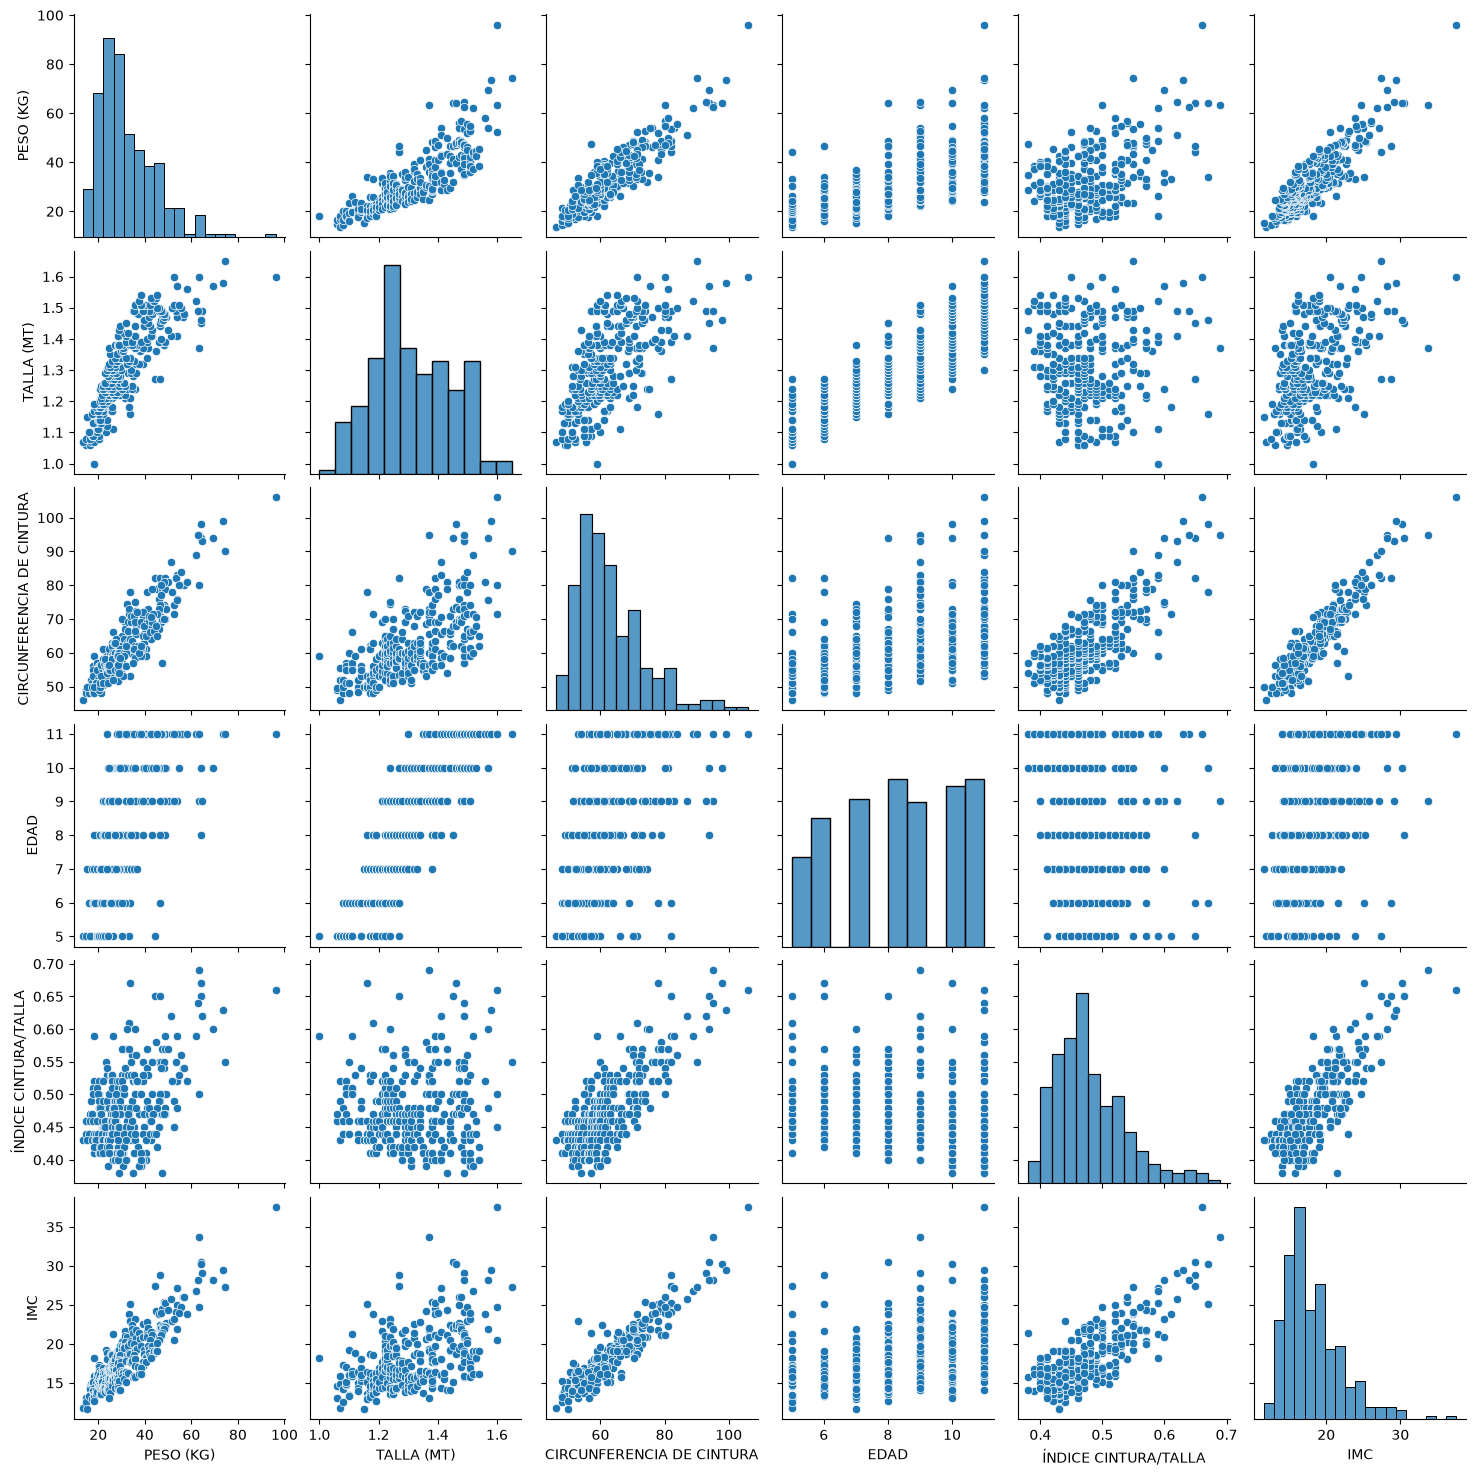

In [8]:
sns.pairplot(df_numeric)

In [9]:
#2.- Seleccionar las variables X y y
#Se decide que el modelo prediga los valores del PESO (KG)
y =  df_numeric ["PESO (KG)"] #Y ES UNA SERIE 
X = df_numeric [["CIRCUNFERENCIA DE CINTURA"]] #DATAFRAME SE ANIDA DENTRO DE OTRA [[]] DONDE X ES UNA MATRIZ
print(y.shape, X.shape)

(313,) (313, 1)


In [12]:
#3.- Crear el modelo de Regresion 
model = LinearRegression()
type(model)

sklearn.linear_model._base.LinearRegression

In [13]:
#El modelo se ajusta a las variables
model.fit(X,y)

LinearRegression()

En este punto el modelo ya esta entrenado

In [14]:
b0=model.intercept_            #b0
b1=model.coef_                 #b1    (derivada)
print(b0,b1)

-34.690094691235906 [1.0705755]


y(est)=-34.69 + 1.07X1

In [15]:
#Primeras predicciones
y_pred = model.predict(X)
y_pred

array([28.47385997, 17.76810495, 18.3033927 , 14.55637844, 20.97983145,
       24.72684571, 20.97983145, 16.69752944, 18.83868045, 26.33270897,
       19.90925595, 25.26213347, 24.19155796, 16.69752944, 29.54443548,
       19.90925595, 16.69752944, 25.26213347, 26.33270897, 35.96788849,
       24.19155796, 28.47385997, 20.97983145, 18.83868045, 17.23281719,
       20.97983145, 22.05040696, 24.19155796, 30.61501098, 25.26213347,
       24.19155796, 18.83868045, 48.81479453, 18.83868045, 22.05040696,
       19.3739682 , 18.3033927 , 18.83868045, 31.68558648, 22.05040696,
       19.90925595, 31.15029873, 18.83868045, 30.61501098, 16.69752944,
       20.97983145, 22.05040696, 41.85605376, 16.69752944, 24.19155796,
       19.90925595, 23.12098246, 25.26213347, 32.75616198, 23.12098246,
       27.40328447, 24.19155796, 17.76810495, 24.19155796, 27.40328447,
       18.83868045, 28.47385997, 28.47385997, 24.72684571, 18.83868045,
       22.05040696, 24.19155796, 39.179615  , 29.54443548, 32.75

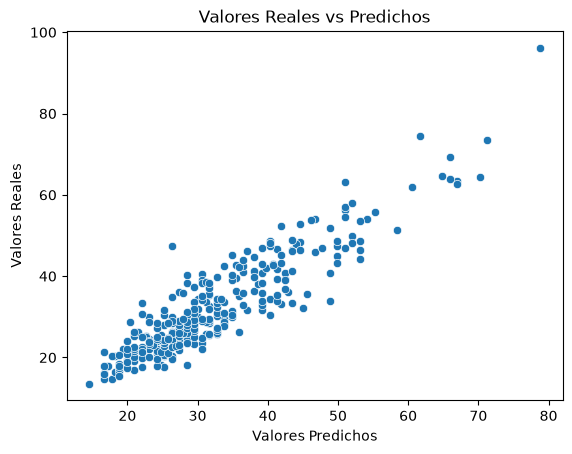

In [16]:
#Graficar la precision de las predicciones
sns.scatterplot(x=y_pred, y=y)
plt.title("Valores Reales vs Predichos")
plt.xlabel("Valores Predichos")
plt.ylabel("Valores Reales")
plt.show()

In [17]:
#Calcular metricas
r2=r2_score(y,y_pred)
mae = mean_absolute_error(y,y_pred)
mse= mean_squared_error(y,y_pred)
print(f"Valor de r2={r2}, Valor de mae={mae}, Valor de mse={mse}")

Valor de r2=0.8336815214773977, Valor de mae=3.7726569906900735, Valor de mse=24.326421241641476


Tarea: 
Infografia: "r2, mae, mse" (metricas)
Cuestionario de 10 preguntas en la libreta "Analisis residual (en regresion)"

In [18]:
#Definir los residuos
residuos= y - y_pred
print(residuos.shape)
residuos

(313,)


0     -10.223860
1      -3.068105
2      -1.853393
3      -1.006378
4      -4.029831
         ...    
308     2.303120
309    10.543946
310    12.244054
311    17.409091
312    12.788299
Name: PESO (KG), Length: 313, dtype: float64

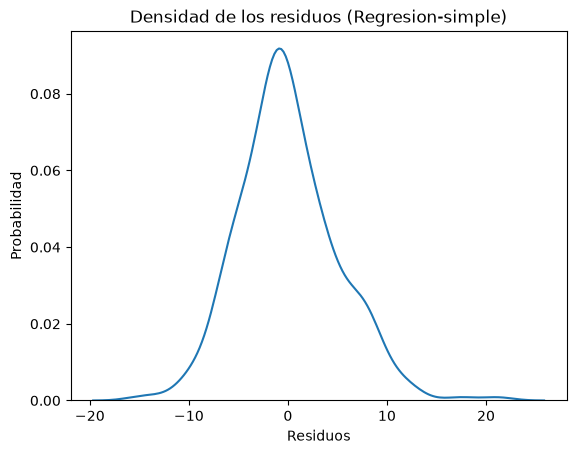

In [20]:
#1.- Graficar la distribución de los residuos
sns.kdeplot(residuos)
plt.title("Densidad de los residuos (Regresion-simple)")
plt.xlabel("Residuos")
plt.ylabel("Probabilidad")
plt.savefig("../../graphics/densidad_residuos_simple_regression.png")
plt.show()